Convert CSV

In [ ]:
# === Merge banyak log -> CSV dengan deduplikasi aman ===
# - Skip file yang 100% identik (berdasarkan SHA256)
# - Hapus duplikat baris hanya jika (time,node,message) identik
# Colab/Jupyter-friendly (tanpa argparse)

import re, csv, os, gzip, glob, hashlib
from pathlib import Path

# ----------------- CONFIG -----------------
INPUTS = [
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/tau3/mob5/DTWRL301.txt",














    # "/content/logs/*.txt",
]
OUTPUT_CSV = "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/tau3/mob5/DTWRL301.csv"

# Jika True: file dengan hash identik akan dilewati (tidak diproses ulang)
SKIP_DUPLICATE_FILES = True

# Dedupe baris: "full" = (time,node,message) identik; "raw_line" = teks baris mentah identik
DEDUPE_MODE = "full"     # rekomendasi: "full"

ZIP_OUTPUT = True
PROGRESS_EVERY = 200_000
# ------------------------------------------

LOG_PATTERN = re.compile(r"(?P<time>\d{2}:\d{2}\.\d{3})\s+ID:(?P<node>\d+)\s+(?P<message>.*)")

def expand_inputs(patterns):
    paths = []
    for pat in patterns:
        if any(ch in pat for ch in "*?[]"):
            paths.extend(glob.glob(pat))
        else:
            paths.append(pat)
    return sorted({str(Path(p)) for p in paths})

def file_sha256(path, chunk_size=1<<20):
    h = hashlib.sha256()
    opener, mode = (gzip.open, "rb") if str(path).endswith(".gz") else (open, "rb")
    with opener(path, mode) as f:
        while True:
            b = f.read(chunk_size)
            if not b: break
            h.update(b)
    return h.hexdigest()

def iter_lines(paths):
    """Iter semua baris dari daftar file, hormati .gz."""
    for p in paths:
        path = Path(p)
        if not path.exists():
            print(f"[WARN] Skip, not found: {path}")
            continue
        if path.suffix == ".gz":
            opener, mode = gzip.open, "rt"
        else:
            opener, mode = open, "r"
        with opener(path, mode, encoding="utf-8", errors="ignore") as f:
            for line in f:
                yield line

def convert():
    input_files = expand_inputs(INPUTS)
    if not input_files:
        raise SystemExit("[ERROR] Tidak ada file yang cocok dengan INPUTS.")

    # 1) Opsi: skip file identik
    final_files = []
    seen_hashes = set()
    for fp in input_files:
        if not SKIP_DUPLICATE_FILES:
            final_files.append(fp)
            continue
        try:
            h = file_sha256(fp)
        except Exception as e:
            print(f"[WARN] Gagal hash {fp}: {e}. Tetap diproses.")
            final_files.append(fp)
            continue
        if h in seen_hashes:
            print(f"[INFO] Skip file duplikat (hash sama): {fp}")
        else:
            seen_hashes.add(h)
            final_files.append(fp)

    if not final_files:
        raise SystemExit("[ERROR] Semua file input terdeteksi duplikat & dilewati.")

    # 2) Tulis header output
    Path(OUTPUT_CSV).parent.mkdir(parents=True, exist_ok=True)
    with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
        csv.writer(f).writerow(["time", "node", "message"])

    # 3) Dedupe baris
    total_parsed = 0
    written = 0
    if DEDUPE_MODE == "raw_line":
        seen_lines = set()
        with open(OUTPUT_CSV, "a", newline="", encoding="utf-8") as f_out:
            w = csv.writer(f_out)
            for line in iter_lines(final_files):
                raw = line.rstrip("\n")
                if raw in seen_lines:
                    continue
                m = LOG_PATTERN.search(line)
                if not m:
                    continue
                seen_lines.add(raw)
                total_parsed += 1
                w.writerow([m.group("time"), m.group("node"), m.group("message").strip()])
                written += 1
                if total_parsed % PROGRESS_EVERY == 0:
                    print(f"[INFO] Parsed {total_parsed:,} lines...")
    else:
        # "full" = dedupe hanya jika (time,node,message) identik
        seen_full = set()
        with open(OUTPUT_CSV, "a", newline="", encoding="utf-8") as f_out:
            w = csv.writer(f_out)
            for line in iter_lines(final_files):
                m = LOG_PATTERN.search(line)
                if not m:
                    continue
                t = m.group("time")
                n = m.group("node")
                msg = m.group("message").strip()
                key = (t, n, msg)
                if key in seen_full:
                    continue
                seen_full.add(key)
                total_parsed += 1
                w.writerow([t, n, msg])
                written += 1
                if total_parsed % PROGRESS_EVERY == 0:
                    print(f"[INFO] Parsed {total_parsed:,} lines...")

    print(f"[DONE] Parsed lines      : {total_parsed:,}")
    print(f"[DONE] Written rows      : {written:,}")
    print(f"[DONE] CSV saved to      : {OUTPUT_CSV}")

    if ZIP_OUTPUT:
        import gzip
        gz_path = OUTPUT_CSV + ".gz"
        with open(OUTPUT_CSV, "rb") as fin, gzip.open(gz_path, "wb") as fout:
            fout.writelines(fin)
        print(f"[DONE] GZ copy saved to  : {gz_path}")

convert()


[INFO] Parsed 200,000 lines...
[DONE] Parsed lines      : 211,271
[DONE] Written rows      : 211,271
[DONE] CSV saved to      : /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/tau3/mob5/DTWRL301.csv
[DONE] GZ copy saved to  : /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/tau3/mob5/DTWRL301.csv.gz


Analisa Transmisi tiap Node

Total rows: 73826
Index(['time', 'node', 'message'], dtype='object')

Rows TC: 22877
Rows UDP: 2736
Rows Sent: 3590

TC parsed shape: (22877, 12)
   csv_node  tau  tgt  action  invT     dE   dE_mJ   dEC  instab  evid    eps  \
0         5  6.0  6.0       1  0.00  0.062  339.82  1.82   0.014     2  0.059   
1        17  6.0  6.0       0  0.15  0.061  339.72  1.67   0.098     2  0.059   
2         9  6.0  6.0       0  0.15  0.061  339.71  1.66   0.098     2  0.059   
3         1  6.0  6.0       1  0.00  0.063  340.48  2.30   0.015     2  0.059   
4        19  6.0  6.0       0  0.00  0.063  341.00  2.72   0.015     3  0.059   

        time  
0  00:11.844  
1  00:11.846  
2  00:11.847  
3  00:11.847  
4  00:11.847  

TC parsed valid rows: 22877

UDP parsed shape: (2674, 6)
   csv_node       time  seq  delay  rssi  \
2        14  00:22.391  0.0    NaN -55.0   
3        14  00:22.553  0.0    NaN -64.0   
4        14  00:22.596  0.0    NaN -76.0   
5        14  00:22.658  0.0   54.0 -63.0   

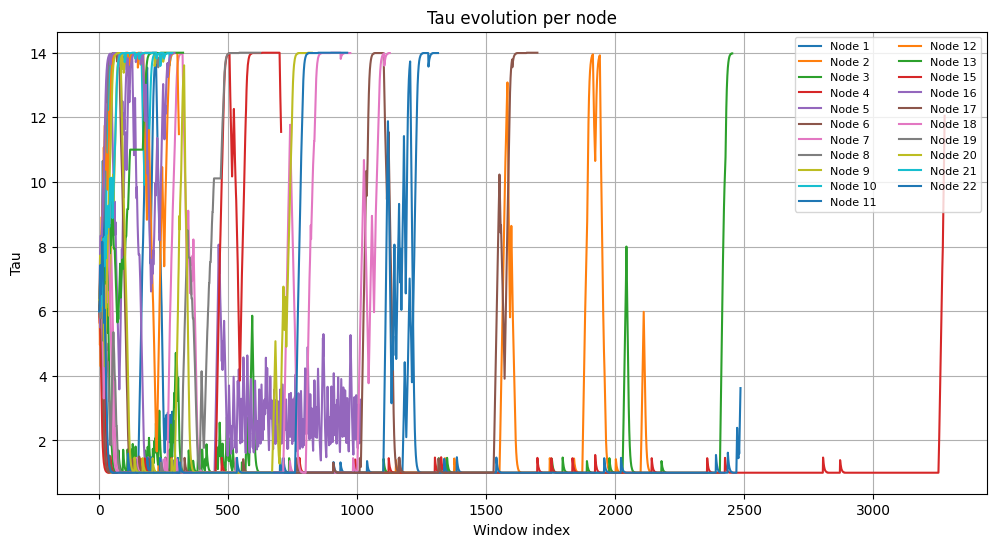


===== RECV COUNTS =====
    src_node  recv_count
0          1         154
1          2         145
2          3         135
3          4          93
4          5         154
5          6         171
6          7         172
7          8          73
8          9         171
9         10         169
10        11          38
11        13         171
12        15         172
13        17         172
14        18         171
15        19         172
16        21         171
17        22         170

===== SENT vs RECV =====
    node  sent_count  recv_count  delivery
0      1         171       154.0      90.1
1      2         170       145.0      85.3
2      3         171       135.0      78.9
3      4         170        93.0      54.7
4      5         171       154.0      90.1
5      6         171       171.0     100.0
6      7         172       172.0     100.0
7      8         171        73.0      42.7
8      9         171       171.0     100.0
9     10         170       169.0      99.4
1

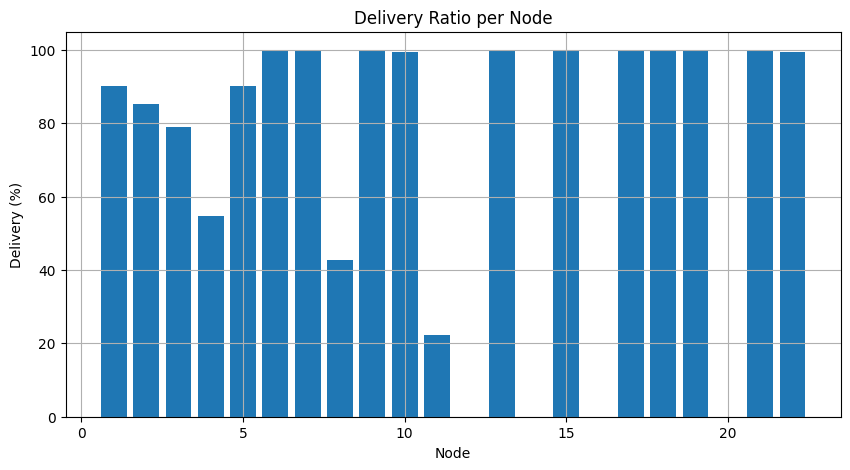

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# ===============================
# 1. LOAD DATA
# ===============================
file_path = "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/30 Maret/DTWRL11.csv"
df = pd.read_csv(file_path)

print("Total rows:", len(df))
print(df.columns)

# pastikan kolom message string
df["message"] = df["message"].astype(str)

# ===============================
# 2. FILTER LOG
# ===============================
tc = df[df["message"].str.contains(r"\bTC,", na=False)].copy()
udp = df[df["message"].str.contains("UDP-Server", na=False)].copy()
sent = df[df["message"].str.contains("Sent Seq", na=False)].copy()

print("\nRows TC:", len(tc))
print("Rows UDP:", len(udp))
print("Rows Sent:", len(sent))

# ===============================
# 3. ROBUST TC PARSER
# ===============================
def extract_value(pattern, text, cast=float, default=np.nan):
    m = re.search(pattern, text)
    if not m:
        return default
    try:
        return cast(m.group(1))
    except:
        return default

def parse_tc_row(row):
    msg = row["message"]
    return {
        "csv_node": row["node"],  # node dari kolom CSV
        "tau": extract_value(r"tau=([0-9]+(?:\.[0-9]+)?)", msg, float),
        "tgt": extract_value(r"tgt=([0-9]+(?:\.[0-9]+)?)", msg, float),
        "action": extract_value(r"a=([0-9]+)", msg, int),
        "invT": extract_value(r"invT=([0-9]+(?:\.[0-9]+)?)", msg, float),
        "dE": extract_value(r"dE=([0-9]+(?:\.[0-9]+)?)", msg, float),
        "dE_mJ": extract_value(r"dE_mJ=([0-9]+(?:\.[0-9]+)?)", msg, float),
        "dEC": extract_value(r"dEC=([0-9]+(?:\.[0-9]+)?)", msg, float),
        "instab": extract_value(r"I=([0-9]+(?:\.[0-9]+)?)", msg, float),
        "evid": extract_value(r"evid=([0-9]+)", msg, int),
        "eps": extract_value(r"eps=([0-9]+(?:\.[0-9]+)?)", msg, float),
        "time": row["time"],
    }

tc_df = pd.DataFrame([parse_tc_row(row) for _, row in tc.iterrows()])

print("\nTC parsed shape:", tc_df.shape)
print(tc_df.head())

# buang baris yang gagal parse total
tc_df = tc_df.dropna(subset=["tau", "action", "evid"], how="any").copy()

print("\nTC parsed valid rows:", len(tc_df))

# ===============================
# 4. PARSE UDP SERVER LOG ROBUST
# ===============================
def parse_udp_row(row):
    msg = row["message"]

    m_seq = re.search(r"Seq=([0-9]+)", msg)
    m_delay = re.search(r"Delay=([0-9]+)ms", msg)
    m_rssi = re.search(r"RSSI=(-?[0-9]+)dBm", msg)

    return {
        "csv_node": row["node"],   # node server, biasanya root
        "time": row["time"],
        "seq": int(m_seq.group(1)) if m_seq else np.nan,
        "delay": int(m_delay.group(1)) if m_delay else np.nan,
        "rssi": int(m_rssi.group(1)) if m_rssi else np.nan,
        "message": msg,
    }

udp_df = pd.DataFrame([parse_udp_row(row) for _, row in udp.iterrows()])
udp_df = udp_df.dropna(subset=["seq"], how="any").copy()

print("\nUDP parsed shape:", udp_df.shape)
print(udp_df.head())

# ===============================
# 5. SENT COUNT PER NODE
# ===============================
# karena kolom node di CSV sudah tersedia, ini lebih aman
sent_counts = sent.groupby("node").size().rename("sent_count").reset_index()
print("\n===== SENT COUNTS =====")
print(sent_counts)

# ===============================
# 6. TC SUMMARY PER NODE
# ===============================
results = []

for node_id in sorted(tc_df["csv_node"].dropna().unique()):
    sub = tc_df[tc_df["csv_node"] == node_id]

    results.append({
        "node": int(node_id),
        "tau_mean": sub["tau"].mean(),
        "tau_last": sub["tau"].iloc[-1],
        "tau_min": sub["tau"].min(),
        "tau_max": sub["tau"].max(),
        "evid_zero": int((sub["evid"] == 0).sum()),
        "total_window": int(len(sub)),
        "a_dec": int((sub["action"] == 0).sum()),
        "a_inc": int((sub["action"] == 1).sum()),
        "instab_mean": sub["instab"].mean(),
        "invT_mean": sub["invT"].mean(),
        "dE_mean": sub["dE"].mean(),
        "dE_mJ_mean": sub["dE_mJ"].mean(),
        "dEC_mean": sub["dEC"].mean(),
        "eps_last": sub["eps"].iloc[-1] if len(sub) > 0 else np.nan,
    })

tc_summary = pd.DataFrame(results).sort_values("node").reset_index(drop=True)

print("\n===== TC SUMMARY =====")
print(tc_summary)

# ===============================
# 7. GLOBAL UDP STATS
# ===============================
if len(udp_df) > 0:
    print("\n===== GLOBAL UDP =====")
    print("Delay Avg:", udp_df["delay"].dropna().mean())
    print("Delay Max:", udp_df["delay"].dropna().max())
    print("RSSI Avg:", udp_df["rssi"].dropna().mean())
else:
    print("\n===== GLOBAL UDP =====")
    print("No UDP rows parsed.")

# ===============================
# 8. TAU VISUALIZATION
# ===============================
plt.figure(figsize=(12, 6))

for node_id in sorted(tc_df["csv_node"].dropna().unique()):
    sub = tc_df[tc_df["csv_node"] == node_id]
    plt.plot(range(len(sub)), sub["tau"].values, label=f"Node {int(node_id)}")

plt.title("Tau evolution per node")
plt.xlabel("Window index")
plt.ylabel("Tau")
plt.legend(ncol=2, fontsize=8)
plt.grid(True)
plt.show()

# ===============================
# 9. PARSE NODE ID DARI IPv6 (SERVER SIDE)
# ===============================
def extract_node_from_ip(msg):
    # contoh: fd00::c30c:0:0:5 → node = 5
    m = re.search(r'::.*:([0-9a-fA-F]+)', msg)
    if m:
        try:
            return int(m.group(1), 16)  # hex → int
        except:
            return np.nan
    return np.nan

udp_df["src_node"] = udp_df["message"].apply(extract_node_from_ip)

# ===============================
# 10. RECV COUNT PER NODE
# ===============================
recv_counts = (
    udp_df.dropna(subset=["src_node"])
    .groupby("src_node")
    .size()
    .rename("recv_count")
    .reset_index()
)

recv_counts["src_node"] = recv_counts["src_node"].astype(int)

print("\n===== RECV COUNTS =====")
print(recv_counts)

# ===============================
# 11. SENT COUNT PER NODE (SUDAH ADA)
# ===============================
sent_counts = (
    sent.groupby("node")
    .size()
    .rename("sent_count")
    .reset_index()
)

# ===============================
# 12. MERGE SENT vs RECV
# ===============================
merged = pd.merge(
    sent_counts,
    recv_counts,
    left_on="node",
    right_on="src_node",
    how="left"
)

merged["recv_count"] = merged["recv_count"].fillna(0)

# ===============================
# 13. DELIVERY RATIO
# ===============================
merged["delivery"] = (
    merged["recv_count"] / merged["sent_count"] * 100
).round(1)

merged = merged[["node", "sent_count", "recv_count", "delivery"]]
merged = merged.sort_values("node")

print("\n===== SENT vs RECV =====")
print(merged)

# ===============================
# 14. VISUALISASI (OPSIONAL)
# ===============================
plt.figure(figsize=(10,5))
plt.bar(merged["node"], merged["delivery"])
plt.xlabel("Node")
plt.ylabel("Delivery (%)")
plt.title("Delivery Ratio per Node")
plt.grid(True)
plt.show()


Tambahan Energy MMDEW dan MRHOF

In [ ]:
import pandas as pd
import re

# ============================================================
# DISPLAY FORMAT TANPA SCIENTIFIC NOTATION
# ============================================================
pd.set_option("display.float_format", "{:,.2f}".format)

# ============================================================
# INPUT FILE
# ============================================================
file_path = "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/CSVTambahan/MRHOFEnergy/MRHOFMob5/MRHOFmob5Interval30E.csv"

# Nama output
output_last_node = "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/CSVTambahan/MRHOFEnergy/MRHOFMob5/last_energy_per_node_MRHOFmob5Interval30.csv"
output_summary = "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/CSVTambahan/MRHOFEnergy/MRHOFMob5/summary_energy_Mob2Interval30.csv"

# ============================================================
# LOAD LOG
# ============================================================
df = pd.read_csv(file_path)

print("Total rows:", len(df))
print("Columns:", df.columns.tolist())

if "message" not in df.columns:
    raise ValueError("Kolom 'message' tidak ditemukan. Cek struktur file CSV.")

# ============================================================
# FILTER EN,TOTAL
# ============================================================
energy_df = df[df["message"].astype(str).str.contains("EN,TOTAL", na=False)].copy()

print("Jumlah baris EN,TOTAL:", len(energy_df))

if energy_df.empty:
    raise ValueError("Tidak ditemukan baris EN,TOTAL pada file log.")

# ============================================================
# PARSE EN,TOTAL
# Format:
# EN,TOTAL,N=21,cpu_mJ=0.62,tx_mJ=0.00,rx_mJ=6.57,total_mJ=7.20
# ============================================================
pattern = re.compile(
    r"EN,TOTAL,N=(?P<node>\d+),"
    r"cpu_mJ=(?P<cpu_mJ>\d+(?:\.\d+)?),"
    r"tx_mJ=(?P<tx_mJ>\d+(?:\.\d+)?),"
    r"rx_mJ=(?P<rx_mJ>\d+(?:\.\d+)?),"
    r"total_mJ=(?P<total_mJ>\d+(?:\.\d+)?)"
)

parsed_rows = []

for idx, row in energy_df.iterrows():
    msg = str(row["message"])
    match = pattern.search(msg)

    if match:
        parsed_rows.append({
            "row_index": idx,
            "time": row["time"] if "time" in df.columns else None,
            "node_from_column": row["node"] if "node" in df.columns else None,
            "node": int(match.group("node")),
            "cpu_mJ": float(match.group("cpu_mJ")),
            "tx_mJ": float(match.group("tx_mJ")),
            "rx_mJ": float(match.group("rx_mJ")),
            "total_mJ": float(match.group("total_mJ")),
            "message": msg
        })

parsed = pd.DataFrame(parsed_rows)

print("Jumlah EN,TOTAL berhasil diparse:", len(parsed))

if parsed.empty:
    raise ValueError("Baris EN,TOTAL ada, tetapi gagal diparse. Cek format log.")

# ============================================================
# AMBIL NILAI EN,TOTAL TERAKHIR PER NODE
# ============================================================
if "time" in parsed.columns and parsed["time"].notna().any():
    parsed = parsed.sort_values(["node", "time", "row_index"])
else:
    parsed = parsed.sort_values(["node", "row_index"])

last_energy_per_node = (
    parsed
    .groupby("node", as_index=False)
    .tail(1)
    .sort_values("node")
    .reset_index(drop=True)
)

# ============================================================
# HITUNG SUMMARY
# ============================================================
summary = {
    "num_nodes": last_energy_per_node["node"].nunique(),

    # Total network energy
    "network_cpu_mJ": last_energy_per_node["cpu_mJ"].sum(),
    "network_tx_mJ": last_energy_per_node["tx_mJ"].sum(),
    "network_rx_mJ": last_energy_per_node["rx_mJ"].sum(),
    "network_total_mJ": last_energy_per_node["total_mJ"].sum(),

    # Total network energy dalam Joule
    "network_cpu_J": last_energy_per_node["cpu_mJ"].sum() / 1000,
    "network_tx_J": last_energy_per_node["tx_mJ"].sum() / 1000,
    "network_rx_J": last_energy_per_node["rx_mJ"].sum() / 1000,
    "network_total_J": last_energy_per_node["total_mJ"].sum() / 1000,

    # Average per node
    "avg_cpu_mJ_per_node": last_energy_per_node["cpu_mJ"].mean(),
    "avg_tx_mJ_per_node": last_energy_per_node["tx_mJ"].mean(),
    "avg_rx_mJ_per_node": last_energy_per_node["rx_mJ"].mean(),
    "avg_total_mJ_per_node": last_energy_per_node["total_mJ"].mean(),

    # Average per node dalam Joule
    "avg_cpu_J_per_node": last_energy_per_node["cpu_mJ"].mean() / 1000,
    "avg_tx_J_per_node": last_energy_per_node["tx_mJ"].mean() / 1000,
    "avg_rx_J_per_node": last_energy_per_node["rx_mJ"].mean() / 1000,
    "avg_total_J_per_node": last_energy_per_node["total_mJ"].mean() / 1000,

    # Descriptive statistics
    "std_total_mJ_per_node": last_energy_per_node["total_mJ"].std(),
    "min_total_mJ_per_node": last_energy_per_node["total_mJ"].min(),
    "max_total_mJ_per_node": last_energy_per_node["total_mJ"].max(),

    # Descriptive statistics dalam Joule
    "std_total_J_per_node": last_energy_per_node["total_mJ"].std() / 1000,
    "min_total_J_per_node": last_energy_per_node["total_mJ"].min() / 1000,
    "max_total_J_per_node": last_energy_per_node["total_mJ"].max() / 1000,
}

summary_df = pd.DataFrame([summary])

# ============================================================
# OUTPUT FORMAT HELPERS
# ============================================================
def print_df_no_scientific(df_print, title):
    print(f"\n=== {title} ===")
    print(df_print.to_string(index=False, float_format=lambda x: f"{x:,.2f}"))

def print_summary_no_scientific(summary_df):
    print("\n=== SUMMARY ENERGY ===")
    summary_view = summary_df.T.copy()
    summary_view.columns = ["value"]
    print(summary_view.to_string(float_format=lambda x: f"{x:,.2f}"))

# ============================================================
# PRINT OUTPUT
# ============================================================
print_df_no_scientific(
    last_energy_per_node[[
        "node", "cpu_mJ", "tx_mJ", "rx_mJ", "total_mJ"
    ]],
    "LAST EN,TOTAL PER NODE"
)

print_summary_no_scientific(summary_df)

# ============================================================
# CEK NODE DENGAN ENERGY RENDAH
# ============================================================
low_threshold_mJ = 100000

low_energy_nodes = last_energy_per_node[
    last_energy_per_node["total_mJ"] < low_threshold_mJ
].copy()

if not low_energy_nodes.empty:
    print(f"\n=== WARNING: NODE DENGAN TOTAL ENERGY < {low_threshold_mJ:,.0f} mJ ===")
    print(
        low_energy_nodes[[
            "node", "time", "cpu_mJ", "tx_mJ", "rx_mJ", "total_mJ"
        ]].to_string(index=False, float_format=lambda x: f"{x:,.2f}")
    )
else:
    print(f"\nTidak ada node dengan total energy < {low_threshold_mJ:,.0f} mJ.")

# ============================================================
# SAVE RESULT
# ============================================================
last_energy_per_node.to_csv(output_last_node, index=False)
summary_df.to_csv(output_summary, index=False)

print("\nFile saved:")
print(f"- {output_last_node}")
print(f"- {output_summary}")

Total rows: 132572
Columns: ['time', 'node', 'message']
Jumlah baris EN,TOTAL: 27171
Jumlah EN,TOTAL berhasil diparse: 27171

=== LAST EN,TOTAL PER NODE ===
 node  cpu_mJ  tx_mJ      rx_mJ   total_mJ
    1    0.66   0.28     228.72     229.68
    2  347.87  21.70 200,903.58 201,273.16
    3  477.22  35.68 201,771.18 202,284.10
    4    0.42   0.00      23.83      24.26
    5  495.20  25.41 202,619.24 203,139.88
    6   51.82   6.23  20,179.44  20,237.51
    7  327.22  24.18 202,376.16 202,727.58
    8    0.40   0.00       5.67       6.07
    9    0.40   0.00      54.32      54.72
   10    0.46   0.00      36.47      36.93
   11  532.64  32.17 202,075.12 202,639.94
   12  287.31  28.73 201,006.46 201,322.52
   13    0.95   1.19     254.69     256.84
   14  254.14  25.98 200,550.68 200,830.82
   15    0.89   0.54     255.45     256.88
   16  463.99  29.92 201,057.44 201,551.36
   17  286.43  29.02 201,656.78 201,972.24
   18  210.47  24.39 200,701.64 200,936.50
   19  443.93  48.69 202,3

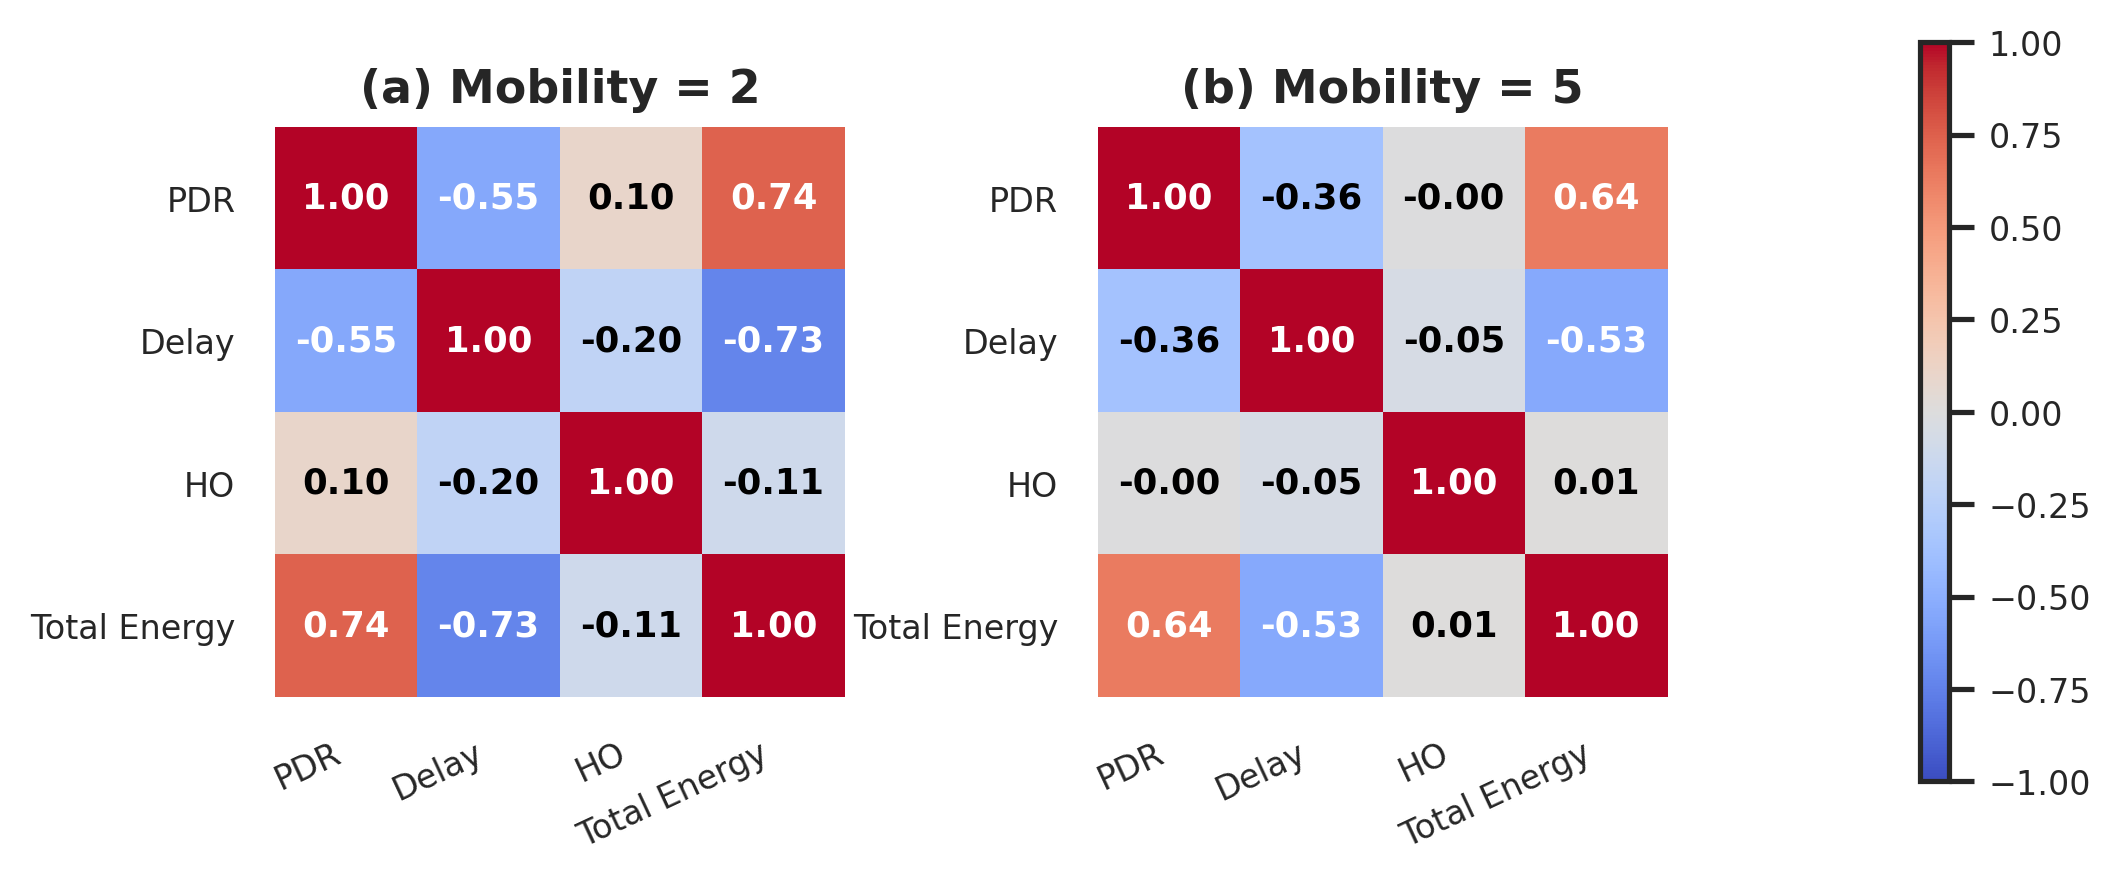

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

metrics = ["PDR", "Delay", "HO", "Total Energy"]

# ============================================================
# STYLE IJIES
# ============================================================
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 9
})

# ============================================================
# FIGURE
# ============================================================
fig = plt.figure(figsize=(7.2, 3.2), dpi=300)

gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1, 1, 0.05],
    wspace=0.65
)

axes = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1])
]

cax = fig.add_subplot(gs[0, 2])

# ============================================================
# LOOP
# ============================================================
for ax, mob, label in zip(
    axes,
    [2, 5],
    ["(a) Mobility = 2", "(b) Mobility = 5"]
):

    corr = data[data["Mobility"] == mob][metrics].corr(method="pearson")

    im = ax.imshow(
        corr,
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    # ==========================
    # TICKS
    # ==========================
    ax.set_xticks(np.arange(len(metrics)))
    ax.set_yticks(np.arange(len(metrics)))

    ax.set_xticklabels(metrics, rotation=25, ha="right")
    ax.set_yticklabels(metrics)

    # ==========================
    # ANGKA KORELASI
    # ==========================
    for i in range(len(metrics)):
        for j in range(len(metrics)):

            value = corr.iloc[i, j]

            # warna otomatis
            color = "white" if abs(value) >= 0.50 else "black"

            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8.5,
                fontweight="bold",
                color=color
            )

    # ==========================
    # TITLE
    # ==========================
    ax.set_title(
        label,
        fontsize=11,
        fontweight="bold",
        pad=6
    )

    # ==========================
    # BORDER CLEAN
    # ==========================
    for spine in ax.spines.values():
        spine.set_visible(False)

# ============================================================
# COLORBAR
# ============================================================
cbar = fig.colorbar(im, cax=cax)
cbar.ax.tick_params(labelsize=8)

# ============================================================
# SAVE
# ============================================================
plt.savefig(
    "pearson_correlation_IJIES_style.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

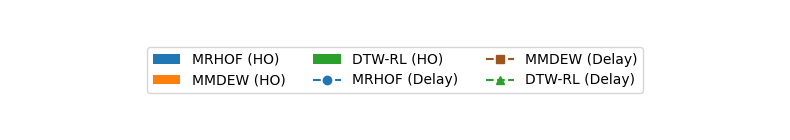

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# =====================================================
# FIGURE KHUSUS LEGEND
# =====================================================
fig, ax = plt.subplots(figsize=(8, 1.5))
ax.axis('off')

legend_handles = [

    # ---------------- PDR ----------------
    Patch(
        facecolor='#1f77b4',
        label='MRHOF (HO)'
    ),

    Patch(
        facecolor='#ff7f0e',
        label='MMDEW (HO)'
    ),

    Patch(
        facecolor='#2ca02c',
        label='DTW-RL (HO)'
    ),

    # ---------------- HO ----------------
    Line2D(
        [0], [0],
        color='#1f77b4',
        linestyle='--',
        marker='o',
        linewidth=1.5,
        markersize=6,
        label='MRHOF (Delay)'
    ),

    Line2D(
        [0], [0],
        color='#9C5420',
        linestyle='--',
        marker='s',
        linewidth=1.5,
        markersize=6,
        label='MMDEW (Delay)'
    ),

    Line2D(
        [0], [0],
        color='#2ca02c',
        linestyle='--',
        marker='^',
        linewidth=1.5,
        markersize=6,
        label='DTW-RL (Delay)'
    )
]

fig.legend(
    handles=legend_handles,
    loc='center',
    ncol=3,
    frameon=True,
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    "legend_pdr_ho.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from pathlib import Path

np.random.seed(42)
N_NODES=12; N_FRAMES=90; AREA_W=100; AREA_H=100; SINK_ID=0
sink_pos=np.array([50.0,92.0]); COMM_RANGE=45.0
TAU_MIN=5; TAU_MAX=30; TAU_INIT=12; ALPHA_TAU=0.35
W_ETX=0.35; W_ENERGY=0.25; W_SNR=0.25; W_HO=0.15
pos=np.column_stack([np.random.uniform(10,90,N_NODES),np.random.uniform(10,75,N_NODES)])
pos[SINK_ID]=sink_pos
vel=np.random.normal(0,1.0,size=(N_NODES,2)); vel[SINK_ID]=0
energy=np.ones(N_NODES)*100.0; energy[SINK_ID]=999.0
parent=np.full(N_NODES,-1); handover_count=np.zeros(N_NODES,dtype=int)
tau=np.ones(N_NODES)*TAU_INIT; next_eval=np.zeros(N_NODES,dtype=int)

def normalize(x):
    x=np.asarray(x,dtype=float)
    if len(x)==0: return x
    mn,mx=np.min(x),np.max(x)
    return np.zeros_like(x) if mx-mn<1e-9 else (x-mn)/(mx-mn)

def dist(a,b): return np.linalg.norm(a-b)

def metrics(i,j):
    d=dist(pos[i],pos[j])
    if d>COMM_RANGE: return None
    etx=np.clip(1+4*(d/COMM_RANGE)**2+np.random.normal(0,0.08),1,6)
    snr=np.clip(35-28*(d/COMM_RANGE)+np.random.normal(0,1.5),1,35)
    pe=1-min(energy[j]/100,1)
    ho=handover_count[i]/max(1,np.max(handover_count)+1)
    return etx,pe,snr,ho

def choose_parent(i):
    cand=[]; ms=[]
    for j in range(N_NODES):
        if i==j: continue
        m=metrics(i,j)
        if m is not None:
            cand.append(j); ms.append(m)
    if not cand: return -1
    ms=np.array(ms)
    cost=W_ETX*normalize(ms[:,0])+W_ENERGY*normalize(ms[:,1])+W_SNR*(1-normalize(ms[:,2]))+W_HO*normalize(ms[:,3])
    return cand[int(np.argmin(cost))]

def tau_update(i, ho):
    residual=np.clip(energy[i]/100,0,1)
    if ho: target=max(TAU_MIN,tau[i]-5)
    elif residual<0.35: target=max(TAU_MIN,tau[i]-3)
    else: target=min(TAU_MAX,tau[i]+2)
    tau[i]=np.clip((1-ALPHA_TAU)*tau[i]+ALPHA_TAU*target,TAU_MIN,TAU_MAX)

def step(frame):
    for i in range(1,N_NODES):
        vel[i]+=np.random.normal(0,0.18,size=2)
        sp=np.linalg.norm(vel[i])
        if sp>1.7: vel[i]=vel[i]/sp*1.7
        pos[i]+=vel[i]*0.8
        if pos[i,0]<5 or pos[i,0]>AREA_W-5: vel[i,0]*=-1
        if pos[i,1]<5 or pos[i,1]>AREA_H-5: vel[i,1]*=-1
        pos[i,0]=np.clip(pos[i,0],5,AREA_W-5); pos[i,1]=np.clip(pos[i,1],5,AREA_H-5)
        energy[i]=max(0, energy[i]-np.random.uniform(0.01,0.04)-(0.025 if parent[i]!=-1 else 0))
    for i in range(1,N_NODES):
        if frame>=next_eval[i]:
            old=parent[i]; new=choose_parent(i)
            ho=(old!=-1 and new!=-1 and new!=old)
            if ho: handover_count[i]+=1
            parent[i]=new
            tau_update(i,ho)
            next_eval[i]=frame+int(round(tau[i]))

fig,ax=plt.subplots(figsize=(7,7),dpi=100)

def animate(frame):
    step(frame); ax.clear(); ax.set_xlim(0,AREA_W); ax.set_ylim(0,AREA_H)
    ax.set_title(f'DTW-RL + MMDEW Simulation | frame={frame} | avg tau={np.mean(tau[1:]):.1f} | HO={np.sum(handover_count[1:])}', fontsize=9)
    ax.grid(True,alpha=.25); ax.set_xlabel('X'); ax.set_ylabel('Y')
    ax.add_patch(plt.Circle(sink_pos,COMM_RANGE,fill=False,ls='--',alpha=.22))
    for i in range(1,N_NODES):
        p=parent[i]
        if p>=0: ax.plot([pos[i,0],pos[p,0]],[pos[i,1],pos[p,1]],lw=1,alpha=.55)
    sizes=55+110*np.clip(energy/100,0,1)
    ax.scatter(pos[1:,0],pos[1:,1],s=sizes[1:],alpha=.88,label='Sensor node')
    ax.scatter([sink_pos[0]],[sink_pos[1]],s=260,marker='*',label='Sink/root')
    for i in range(N_NODES):
        ax.text(pos[i,0]+1,pos[i,1]+1,('Sink' if i==0 else f'N{i}\ntau={tau[i]:.0f}'),fontsize=6)
    ax.text(2,3,'MMDEW: minimum multi-metric parent cost\nDTW-RL: adaptive time control tau\nSmall tau = frequent evaluation\nLarge tau = stable routing interval',fontsize=7,va='bottom',bbox=dict(boxstyle='round',alpha=.13))
    ax.legend(loc='lower right',fontsize=7)

ani=FuncAnimation(fig,animate,frames=N_FRAMES,interval=120,repeat=True)
gif_path=Path('/content/drive/MyDrive/Cooja/dtw_rl_mmdew_simulation.gif')
ani.save(gif_path,writer=PillowWriter(fps=8))
plt.close(fig)
print(gif_path)


/content/drive/MyDrive/Cooja/dtw_rl_mmdew_simulation.gif


Energi FInallll

In [2]:
import pandas as pd
import re
from pathlib import Path

# ============================================================
# DISPLAY FORMAT TANPA SCIENTIFIC NOTATION
# ============================================================
pd.set_option("display.float_format", "{:,.2f}".format)

# ============================================================
# KONFIGURASI INPUT
# Masukkan 5 file CSV di sini
# ============================================================
input_files = [
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli:Trajektori Berubah/CSV/dtwrlcomplete/Mob2/10/DTWRL101.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli:Trajektori Berubah/CSV/dtwrlcomplete/Mob2/10/DTWRL102.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli:Trajektori Berubah/CSV/dtwrlcomplete/Mob2/10/DTWRL103.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli:Trajektori Berubah/CSV/dtwrlcomplete/Mob2/10/DTWRL104.csv",
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli:Trajektori Berubah/CSV/dtwrlcomplete/Mob2/10/DTWRL105.csv",
]

# Folder output
output_dir = Path(
    "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli:Trajektori Berubah/CSV/dtwrlcomplete/Mob2/ProcessedEnergy"
)

output_dir.mkdir(parents=True, exist_ok=True)

# Output gabungan
output_combined_summary = output_dir / "combined_summary_energy_MRHOFmob5.csv"
output_combined_nodes = output_dir / "combined_last_energy_per_node_MRHOFmob5.csv"

# Threshold energy rendah
low_threshold_mJ = 100000

# ============================================================
# REGEX PARSING EN,TOTAL
# ============================================================
pattern = re.compile(
    r"EN,TOTAL,N=(?P<node>\d+),"
    r"cpu_mJ=(?P<cpu_mJ>\d+(?:\.\d+)?),"
    r"tx_mJ=(?P<tx_mJ>\d+(?:\.\d+)?),"
    r"rx_mJ=(?P<rx_mJ>\d+(?:\.\d+)?),"
    r"total_mJ=(?P<total_mJ>\d+(?:\.\d+)?)"
)

# ============================================================
# HELPER: EKSTRAK INFORMASI DARI NAMA FILE
# Contoh:
# MRHOFmob5Interval30E.csv
# protocol = MRHOF
# mobility = 5
# interval = 30
# ============================================================
def extract_experiment_info(file_path):
    file_name = Path(file_path).stem

    protocol_match = re.search(r"^(MRHOF|MMDEW|DTW[-_]?RL)", file_name, re.IGNORECASE)
    mobility_match = re.search(r"mob(?:ility)?[_-]?(\d+)", file_name, re.IGNORECASE)
    interval_match = re.search(r"interval[_-]?(\d+)", file_name, re.IGNORECASE)

    protocol = (
        protocol_match.group(1).upper().replace("_", "-")
        if protocol_match else "Unknown"
    )

    mobility = (
        int(mobility_match.group(1))
        if mobility_match else None
    )

    interval = (
        int(interval_match.group(1))
        if interval_match else None
    )

    return {
        "experiment": file_name,
        "protocol": protocol,
        "mobility": mobility,
        "interval": interval
    }

# ============================================================
# HELPER: PRINT DATAFRAME
# ============================================================
def print_df_no_scientific(df_print, title):
    print(f"\n=== {title} ===")
    print(
        df_print.to_string(
            index=False,
            float_format=lambda x: f"{x:,.2f}"
        )
    )

def print_summary_no_scientific(summary_df, title):
    print(f"\n=== {title} ===")
    summary_view = summary_df.T.copy()
    summary_view.columns = ["value"]

    print(
        summary_view.to_string(
            float_format=lambda x: f"{x:,.2f}"
        )
    )

# ============================================================
# FUNGSI UTAMA PEMROSESAN SATU FILE
# ============================================================
def process_energy_file(file_path, output_dir, low_threshold_mJ=100000):
    file_path = Path(file_path)

    if not file_path.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {file_path}")

    experiment_info = extract_experiment_info(file_path)

    experiment_name = experiment_info["experiment"]
    protocol = experiment_info["protocol"]
    mobility = experiment_info["mobility"]
    interval = experiment_info["interval"]

    print("\n" + "=" * 80)
    print(f"PROCESSING: {file_path.name}")
    print("=" * 80)

    # ========================================================
    # LOAD CSV
    # ========================================================
    df = pd.read_csv(file_path)

    print("Total rows:", len(df))
    print("Columns:", df.columns.tolist())

    if "message" not in df.columns:
        raise ValueError(
            f"Kolom 'message' tidak ditemukan pada file: {file_path.name}"
        )

    # ========================================================
    # FILTER EN,TOTAL
    # ========================================================
    energy_df = df[
        df["message"]
        .astype(str)
        .str.contains("EN,TOTAL", na=False)
    ].copy()

    print("Jumlah baris EN,TOTAL:", len(energy_df))

    if energy_df.empty:
        raise ValueError(
            f"Tidak ditemukan baris EN,TOTAL pada file: {file_path.name}"
        )

    # ========================================================
    # PARSE EN,TOTAL
    # ========================================================
    parsed_rows = []

    for idx, row in energy_df.iterrows():
        msg = str(row["message"])
        match = pattern.search(msg)

        if match:
            parsed_rows.append({
                "experiment": experiment_name,
                "protocol": protocol,
                "mobility": mobility,
                "interval": interval,
                "source_file": file_path.name,
                "row_index": idx,
                "time": row["time"] if "time" in df.columns else None,
                "node_from_column": (
                    row["node"] if "node" in df.columns else None
                ),
                "node": int(match.group("node")),
                "cpu_mJ": float(match.group("cpu_mJ")),
                "tx_mJ": float(match.group("tx_mJ")),
                "rx_mJ": float(match.group("rx_mJ")),
                "total_mJ": float(match.group("total_mJ")),
                "message": msg
            })

    parsed = pd.DataFrame(parsed_rows)

    print("Jumlah EN,TOTAL berhasil diparse:", len(parsed))

    if parsed.empty:
        raise ValueError(
            f"Baris EN,TOTAL ditemukan tetapi gagal diparse: {file_path.name}"
        )

    # ========================================================
    # KONVERSI TIME KE NUMERIK JIKA MEMUNGKINKAN
    # ========================================================
    if "time" in parsed.columns:
        parsed["time_numeric"] = pd.to_numeric(
            parsed["time"],
            errors="coerce"
        )
    else:
        parsed["time_numeric"] = None

    # ========================================================
    # AMBIL NILAI TERAKHIR PER NODE
    # ========================================================
    if parsed["time_numeric"].notna().any():
        parsed = parsed.sort_values(
            ["node", "time_numeric", "row_index"]
        )
    else:
        parsed = parsed.sort_values(
            ["node", "row_index"]
        )

    last_energy_per_node = (
        parsed
        .groupby("node", as_index=False)
        .tail(1)
        .sort_values("node")
        .reset_index(drop=True)
    )

    # ========================================================
    # HITUNG SUMMARY
    # ========================================================
    num_nodes = last_energy_per_node["node"].nunique()

    network_cpu_mJ = last_energy_per_node["cpu_mJ"].sum()
    network_tx_mJ = last_energy_per_node["tx_mJ"].sum()
    network_rx_mJ = last_energy_per_node["rx_mJ"].sum()
    network_total_mJ = last_energy_per_node["total_mJ"].sum()

    avg_cpu_mJ = last_energy_per_node["cpu_mJ"].mean()
    avg_tx_mJ = last_energy_per_node["tx_mJ"].mean()
    avg_rx_mJ = last_energy_per_node["rx_mJ"].mean()
    avg_total_mJ = last_energy_per_node["total_mJ"].mean()

    std_total_mJ = last_energy_per_node["total_mJ"].std()
    min_total_mJ = last_energy_per_node["total_mJ"].min()
    max_total_mJ = last_energy_per_node["total_mJ"].max()

    summary = {
        "experiment": experiment_name,
        "protocol": protocol,
        "mobility": mobility,
        "interval": interval,
        "source_file": file_path.name,

        "num_nodes": num_nodes,

        # Total network energy dalam mJ
        "network_cpu_mJ": network_cpu_mJ,
        "network_tx_mJ": network_tx_mJ,
        "network_rx_mJ": network_rx_mJ,
        "network_total_mJ": network_total_mJ,

        # Total network energy dalam J
        "network_cpu_J": network_cpu_mJ / 1000,
        "network_tx_J": network_tx_mJ / 1000,
        "network_rx_J": network_rx_mJ / 1000,
        "network_total_J": network_total_mJ / 1000,

        # Rata-rata per node dalam mJ
        "avg_cpu_mJ_per_node": avg_cpu_mJ,
        "avg_tx_mJ_per_node": avg_tx_mJ,
        "avg_rx_mJ_per_node": avg_rx_mJ,
        "avg_total_mJ_per_node": avg_total_mJ,

        # Rata-rata per node dalam J
        "avg_cpu_J_per_node": avg_cpu_mJ / 1000,
        "avg_tx_J_per_node": avg_tx_mJ / 1000,
        "avg_rx_J_per_node": avg_rx_mJ / 1000,
        "avg_total_J_per_node": avg_total_mJ / 1000,

        # Statistik deskriptif dalam mJ
        "std_total_mJ_per_node": std_total_mJ,
        "min_total_mJ_per_node": min_total_mJ,
        "max_total_mJ_per_node": max_total_mJ,

        # Statistik deskriptif dalam J
        "std_total_J_per_node": std_total_mJ / 1000,
        "min_total_J_per_node": min_total_mJ / 1000,
        "max_total_J_per_node": max_total_mJ / 1000,

        # Tambahan indikator pemerataan energi
        "range_total_mJ_per_node": max_total_mJ - min_total_mJ,
        "cv_total_energy_percent": (
            (std_total_mJ / avg_total_mJ) * 100
            if avg_total_mJ != 0 else None
        )
    }

    summary_df = pd.DataFrame([summary])

    # ========================================================
    # NODE ENERGY RENDAH
    # ========================================================
    low_energy_nodes = last_energy_per_node[
        last_energy_per_node["total_mJ"] < low_threshold_mJ
    ].copy()

    summary_df["num_low_energy_nodes"] = len(low_energy_nodes)
    summary_df["low_energy_threshold_mJ"] = low_threshold_mJ

    # ========================================================
    # NAMA FILE OUTPUT OTOMATIS
    # ========================================================
    output_last_node = (
        output_dir /
        f"last_energy_per_node_{experiment_name}.csv"
    )

    output_summary = (
        output_dir /
        f"summary_energy_{experiment_name}.csv"
    )

    output_low_energy = (
        output_dir /
        f"low_energy_nodes_{experiment_name}.csv"
    )

    # ========================================================
    # SIMPAN OUTPUT
    # ========================================================
    last_energy_per_node.to_csv(
        output_last_node,
        index=False
    )

    summary_df.to_csv(
        output_summary,
        index=False
    )

    low_energy_nodes.to_csv(
        output_low_energy,
        index=False
    )

    # ========================================================
    # PRINT OUTPUT
    # ========================================================
    print_df_no_scientific(
        last_energy_per_node[
            [
                "experiment",
                "node",
                "cpu_mJ",
                "tx_mJ",
                "rx_mJ",
                "total_mJ"
            ]
        ],
        f"LAST EN,TOTAL PER NODE — {experiment_name}"
    )

    print_summary_no_scientific(
        summary_df,
        f"SUMMARY ENERGY — {experiment_name}"
    )

    if not low_energy_nodes.empty:
        print(
            f"\nWARNING: {len(low_energy_nodes)} node memiliki "
            f"total energy < {low_threshold_mJ:,.0f} mJ"
        )

        print(
            low_energy_nodes[
                [
                    "node",
                    "time",
                    "cpu_mJ",
                    "tx_mJ",
                    "rx_mJ",
                    "total_mJ"
                ]
            ].to_string(
                index=False,
                float_format=lambda x: f"{x:,.2f}"
            )
        )
    else:
        print(
            f"\nTidak ada node dengan total energy "
            f"< {low_threshold_mJ:,.0f} mJ."
        )

    print("\nFile saved:")
    print(f"- {output_last_node}")
    print(f"- {output_summary}")
    print(f"- {output_low_energy}")

    return last_energy_per_node, summary_df

# ============================================================
# PROSES SELURUH FILE
# ============================================================
all_last_energy = []
all_summaries = []
failed_files = []

for file_path in input_files:
    try:
        last_nodes_df, summary_df = process_energy_file(
            file_path=file_path,
            output_dir=output_dir,
            low_threshold_mJ=low_threshold_mJ
        )

        all_last_energy.append(last_nodes_df)
        all_summaries.append(summary_df)

    except Exception as error:
        print("\n" + "!" * 80)
        print(f"GAGAL MEMPROSES FILE: {file_path}")
        print(f"ERROR: {error}")
        print("!" * 80)

        failed_files.append({
            "file_path": file_path,
            "error": str(error)
        })

# ============================================================
# GABUNGKAN OUTPUT SELURUH EKSPERIMEN
# ============================================================
if all_last_energy:
    combined_last_energy = pd.concat(
        all_last_energy,
        ignore_index=True
    )

    combined_last_energy.to_csv(
        output_combined_nodes,
        index=False
    )

    print(f"\nCombined node output saved:")
    print(f"- {output_combined_nodes}")

if all_summaries:
    combined_summary = pd.concat(
        all_summaries,
        ignore_index=True
    )

    # Urutkan berdasarkan protocol, mobility, dan interval
    sort_columns = [
        col for col in ["protocol", "mobility", "interval"]
        if col in combined_summary.columns
    ]

    if sort_columns:
        combined_summary = combined_summary.sort_values(
            sort_columns,
            na_position="last"
        ).reset_index(drop=True)

    combined_summary.to_csv(
        output_combined_summary,
        index=False
    )

    print_df_no_scientific(
        combined_summary[
            [
                "experiment",
                "protocol",
                "mobility",
                "interval",
                "num_nodes",
                "network_total_mJ",
                "network_total_J",
                "avg_total_mJ_per_node",
                "avg_total_J_per_node",
                "std_total_mJ_per_node",
                "cv_total_energy_percent",
                "num_low_energy_nodes"
            ]
        ],
        "COMBINED SUMMARY ENERGY"
    )

    print(f"\nCombined summary saved:")
    print(f"- {output_combined_summary}")

# ============================================================
# SIMPAN DAFTAR FILE GAGAL
# ============================================================
if failed_files:
    failed_df = pd.DataFrame(failed_files)

    output_failed = output_dir / "failed_energy_files.csv"

    failed_df.to_csv(
        output_failed,
        index=False
    )

    print("\nTerdapat file yang gagal diproses:")
    print(failed_df.to_string(index=False))
    print(f"\nFailed-file report saved:")
    print(f"- {output_failed}")
else:
    print("\nSemua file berhasil diproses.")


PROCESSING: DTWRL101.csv
Total rows: 241512
Columns: ['time', 'node', 'message']
Jumlah baris EN,TOTAL: 0

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
GAGAL MEMPROSES FILE: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli:Trajektori Berubah/CSV/dtwrlcomplete/Mob2/10/DTWRL101.csv
ERROR: Tidak ditemukan baris EN,TOTAL pada file: DTWRL101.csv
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

PROCESSING: DTWRL102.csv
Total rows: 230622
Columns: ['time', 'node', 'message']
Jumlah baris EN,TOTAL: 0

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
GAGAL MEMPROSES FILE: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli:Trajektori Berubah/CSV/dtwrlcomplete/Mob2/10/DTWRL102.csv
ERROR: Tidak ditemukan baris EN,TOTAL pada file: DTWRL102.csv
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

PROCESSING: DTWRL103.csv
Total rows: 268007
Columns: ['time', 'node', '